In [25]:
# 언어 모델 세팅
from langchain_openai import ChatOpenAI

# 언어 모델 생성
llm = ChatOpenAI(model="gpt-4o", temperature=0.01)
llm.invoke("안녕하세요!") # 테스트용. invoke() 함수 안에 stream 작동.

AIMessage(content='안녕하세요! 어떻게 도와드릴까요?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 10, 'prompt_tokens': 10, 'total_tokens': 20, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-2024-08-06', 'system_fingerprint': 'fp_e85bcce457', 'id': 'chatcmpl-EayWTfXKrLF6LFXgZJC42hK09BoEI', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a15833-f944-7a53-8b83-6fb433419c71-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 10, 'output_tokens': 10, 'total_tokens': 20, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}})

In [26]:
# LangGraph 사용해서 신문기자 agent 생성 - 챗봇 -> State 공유 -> messages
# 1. 상태 정의(설계)
from typing import Annotated
from typing_extensions import TypedDict # Dict인데 type: 데이터 타입이 정해짐.
from langgraph.graph.message import add_messages

class State(TypedDict):
    messages:Annotated[list[str], add_messages]

In [27]:
# graph_builder(생성자) 생성
from langgraph.graph import StateGraph,START,END


graph_builder = StateGraph(State)


In [28]:
# 인터넷 검색(덕덕고), 현재 시간 처리.
from langchain_core.tools import tool
from datetime import datetime
import pytz
from langchain_community.tools import DuckDuckGoSearchResults
from langchain_community.utilities import DuckDuckGoSearchAPIWrapper


import bs4
from langchain_community.document_loaders import WebBaseLoader  # 본문 추출할 때...


# 도구 함수 정의
@tool
def get_current_time(timezone: str, location: str) -> str:
    """현재 시각을 반환하는 함수."""
    try:
        tz = pytz.timezone(timezone)
        now = datetime.now(tz).strftime("%Y-%m-%d %H:%M:%S")
        result = f'{timezone} ({location}) 현재시각 {now}'
        # print(result)
        return result
    except pytz.UnknownTimeZoneError:
        return f"알 수 없는 타임존: {timezone}"
   
@tool
def get_web_search(query: str, search_period: str='m') -> str:
    """
    웹 검색을 수행하는 함수.


    Args:
        query (str): 검색어
        search_period (str): 검색 기간 (e.g., "w" for past week (default), "m" for past month, "y" for past year, "d" for past day)


    Returns:
        str: 검색 결과
    """
    wrapper = DuckDuckGoSearchAPIWrapper(
        # region="kr-kr",
        time=search_period
    )


    print('\n-------- WEB SEARCH --------')
    print(query)
    print(search_period)


    search = DuckDuckGoSearchResults(
        api_wrapper=wrapper,
        # source="news",
        results_separator=';\n'
    )


    searched = search.invoke(query)
   
    for i, result in enumerate(searched.split(';\n')):
        print(f'{i+1}. {result}')
   
    return searched # 검색 결과 반환


# 도구 바인딩
tools = [get_current_time, get_web_search]


In [29]:
# 위 선언한 tools(함수) 테스트 진행.
# tools[0].invoke({'timezone':"Asia/Seoul", "location":"부산"})
tools[1].invoke({"query":"구글 아르곤","search_period":"m"})


-------- WEB SEARCH --------
구글 아르곤
m
1. snippet: Oct 1, 2026 · 코레이 카부크추오글루 (Koray Kavukcuoglu) 구글 딥마인드 수석부사장은 "아르곤 수준의 최첨단 기술을 안전하게 공개하기 위해서는 단계적인 접근 ..., title: 구글, 최상위 AI 모델 '제미나이 4 아르곤' 공개… "코딩 능력 1위", link: https://biz.chosun.com/it-science/ict/2026/10/01/XYVWDKSPO5D6PM5XW3V6DYLZQ4/
2. snippet: Oct 1, 2026 · 구글 딥마인드의 수장인 코레이 카부쿠오글루 수석 부사장은 "첨단 기술을 안전하게 공개하려면 단계적인 접근 방식이 필요하다"라며 "개발자, 기업 및 일반 사용자에게 아르곤을 최대한 빨리 제공하기 전에, 초기 테스터들의 피드백을 지속적으로 수집하고 ..., title: 구글, '제미나이 4 아르곤' 공개…성능 1위 탈환에도 "일반 사용 제한"..., link: https://www.aitimes.com/news/articleView.html?idxno=215821
3. snippet: Oct 1, 2026 · [이데일리 신영빈 기자] 구글이 코딩과 금융·법률 등 전문 업무 능력을 끌어올린 차세대 최상위 인공지능 (AI) 모델 ‘제미나이4 아르곤 (Argon)’을 ..., title: 구글 최상위 AI ‘아르곤’ 공개…일반 접근은 제한, link: https://www.edaily.co.kr/News/Read?newsId=02771606645608656
4. snippet: Oct 1, 2026 · 제미나이 4 아르곤 (Gemini 4 Argon)은 구글이 2026년 9월 30일 공개한 새 AI 모델입니다. 구글 AI 중 가장 똑똑한 모델이지만, 아직은 아무나 쓸 수 없어요., title: 제미나이 4 아르곤, 아직 아무나 못 쓰는 이유와 출시일은 언제?, link: https://devwar.tistory.c

'snippet: Oct 1, 2026 · 코레이 카부크추오글루 (Koray Kavukcuoglu) 구글 딥마인드 수석부사장은 "아르곤 수준의 최첨단 기술을 안전하게 공개하기 위해서는 단계적인 접근 ..., title: 구글, 최상위 AI 모델 \'제미나이 4 아르곤\' 공개… "코딩 능력 1위", link: https://biz.chosun.com/it-science/ict/2026/10/01/XYVWDKSPO5D6PM5XW3V6DYLZQ4/;\nsnippet: Oct 1, 2026 · 구글 딥마인드의 수장인 코레이 카부쿠오글루 수석 부사장은 "첨단 기술을 안전하게 공개하려면 단계적인 접근 방식이 필요하다"라며 "개발자, 기업 및 일반 사용자에게 아르곤을 최대한 빨리 제공하기 전에, 초기 테스터들의 피드백을 지속적으로 수집하고 ..., title: 구글, \'제미나이 4 아르곤\' 공개…성능 1위 탈환에도 "일반 사용 제한"..., link: https://www.aitimes.com/news/articleView.html?idxno=215821;\nsnippet: Oct 1, 2026 · [이데일리 신영빈 기자] 구글이 코딩과 금융·법률 등 전문 업무 능력을 끌어올린 차세대 최상위 인공지능 (AI) 모델 ‘제미나이4 아르곤 (Argon)’을 ..., title: 구글 최상위 AI ‘아르곤’ 공개…일반 접근은 제한, link: https://www.edaily.co.kr/News/Read?newsId=02771606645608656;\nsnippet: Oct 1, 2026 · 제미나이 4 아르곤 (Gemini 4 Argon)은 구글이 2026년 9월 30일 공개한 새 AI 모델입니다. 구글 AI 중 가장 똑똑한 모델이지만, 아직은 아무나 쓸 수 없어요., title: 제미나이 4 아르곤, 아직 아무나 못 쓰는 이유와 출시일은 언제?, link: https://devwar.tistory.com/entry/gemini-4-argon-release-summary'

In [30]:
# 함수 목록 만들기
for tool in tools:
    # print(type(tool))
    # print('='*100)
    print(tool.name, tool)

get_current_time name='get_current_time' description='현재 시각을 반환하는 함수.' args_schema=<class 'langchain_core.utils.pydantic.get_current_time'> func=<function get_current_time at 0x000001A1287F75B0>
get_web_search name='get_web_search' description='웹 검색을 수행하는 함수.\n\n\nArgs:\n    query (str): 검색어\n    search_period (str): 검색 기간 (e.g., "w" for past week (default), "m" for past month, "y" for past year, "d" for past day)\n\n\nReturns:\n    str: 검색 결과' args_schema=<class 'langchain_core.utils.pydantic.get_web_search'> func=<function get_web_search at 0x000001A1287F7490>


In [31]:
# LLM과 tool을 엮는다(bind): tool을 사용할 수 있는 LLM 생성
llm_with_tools = llm.bind_tools(tools)


In [32]:
# 노드(함수) generate

def generate(state:State):
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

graph_builder.add_node("generate", generate)    # node 추가하는 설계도 그린 것.

In [33]:
import json
from langchain_core.messages import ToolMessage


class BasicToolNode:
    """
    도구를 실행하는 노드 클래스입니다. 마지막 AIMessage에서 요청된 도구를 실행합니다.
    Attributes:
        tools_by_name (dict): 도구 이름을 키로 하고 도구 객체를 값으로 가지는 사전입니다.
    Methods:
        __init__(tools: list): 도구 객체들의 리스트를 받아서 초기화합니다.
        __call__(inputs: dict): 입력 메시지를 받아서 도구를 실행하고 결과 메시지를 반환합니다.
    """
    """A node that runs the tools requested in the last AIMessage."""


    def __init__(self, tools: list) -> None:    # ①
        self.tools_by_name = {tool.name: tool for tool in tools}


    def __call__(self, inputs: dict):    # ②
        if messages := inputs.get("messages", []):
            # inputs에 messages가 있으면 messages를 가져오고 없으면 빈 리스트를 가져옵니다.
            message = messages[-1]
        else:
            raise ValueError("No message found in input")
        outputs = []
        for tool_call in message.tool_calls:    # ③
            tool_result = self.tools_by_name[tool_call["name"]].invoke(
                tool_call["args"]
            )
            outputs.append(
                ToolMessage(
                    content=json.dumps(tool_result),
                    name=tool_call["name"],
                    tool_call_id=tool_call["id"],
                )
            )
        return {"messages": messages + outputs}


tool_node = BasicToolNode(tools=tools)
graph_builder.add_node("tools", tool_node)


In [34]:
def route_tools(state: State):
    """
    마지막 메시지에 도구 호출이 있는 경우 ToolNode로 라우팅하고,
    그렇지 않은 경우 끝으로 라우팅하기 위해 conditional_edge에서 사용합니다.
    """
    if isinstance(state, list):
        ai_message = state[-1]
    elif messages := state.get("messages", []):
        ai_message = messages[-1]
    else:
        raise ValueError(f"tool_edge 입력 상태에서 메시지를 찾을 수 없습니다: {state}")
    if hasattr(ai_message, "tool_calls") and len(ai_message.tool_calls) > 0:
        return "tools"
    return END


graph_builder.add_edge(START, "generate")


graph_builder.add_conditional_edges(
    "generate",
    route_tools,
    {"tools": "tools", END: END},
)
# 도구가 호출될 때마다 다음 단계를 결정하기 위해 챗봇으로 돌아갑니다.
graph_builder.add_edge("tools", "generate")
graph = graph_builder.compile()


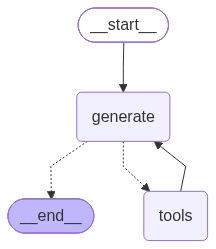

In [35]:
from IPython.display import Image, display


try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass


In [36]:
from langchain_core.messages import AIMessageChunk, HumanMessage


inputs = [HumanMessage(content="지금 서울 몇시야?")]


gathered = None


for msg, metadata in graph.stream({"messages": inputs}, stream_mode="messages"):
    if isinstance(msg, AIMessageChunk):
        print(msg.content, end='')


        if gathered is None:
            gathered = msg
        else:
            gathered = gathered + msg


gathered


지금 서울의 시간은 2026년 10월 20일 오후 4시 26분입니다.

AIMessageChunk(content='지금 서울의 시간은 2026년 10월 20일 오후 4시 26분입니다.', additional_kwargs={}, response_metadata={'model_provider': 'openai', 'finish_reason': 'tool_callsstop', 'model_name': 'gpt-4o-2024-08-06gpt-4o-2024-08-06', 'system_fingerprint': 'fp_09f36310b5fp_09f36310b5', 'service_tier': 'defaultdefault'}, id='lc_run--01a15834-55fc-7792-81b2-e21a7ad24a32', tool_calls=[{'name': 'get_current_time', 'args': {'timezone': 'Asia/Seoul', 'location': '서울'}, 'id': 'call_FnOgQX8FRKotDeioKOKOfSyu', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 373, 'output_tokens': 48, 'total_tokens': 421, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}}, tool_call_chunks=[{'name': 'get_current_time', 'args': '{"timezone":"Asia/Seoul","location":"서울"}', 'id': 'call_FnOgQX8FRKotDeioKOKOfSyu', 'index': 0, 'type': 'tool_call_chunk'}], chunk_position='last')

In [42]:
from langchain_core.messages import AIMessageChunk, SystemMessage


about = "서울월드컵 경기장 잔디 문제"


inputs = [SystemMessage(content=f"""
너는 신문기자이다.
최근 {about}에 대해 비판하는 심층 분석 기사를 쓰려고 한다.  


- 최근 어떤 이슈가 있는지 검색하고, 사람들이 제일 관심있어 할만한 주제를 선정하고, 왜 선정했는지 말해줘.
- 그 내용으로 원고를 작성하기 위한 목차를 만들고, 목차 내용을 채우기 위해 추가로 검색할 내용을 리스트로 정리해봐.
- 검색할 리스트를 토대로 재검색을 한다.
- 목차에 있는 내용을 작성하기 위해 더 검색이 필요한 정보가 있는지 확인하고, 있다면 추가로 검색해라.
- 검색된 결과에 원하는 정보를 찾지 못했다면 다른 검색어로 재검색해도 좋다.


더 이상 검색할 내용이 없다면, 신문 기사 형식으로 최종 기사를 작성하라.
제목, 부제, 리드문, 본문 의 구성으로 작성하라. 본문 내용은 심층 분석 기사에 맞게 구체적이고 깊이 있게 작성해야 한다.
   
""")]


for msg, metadata in graph.stream({"messages": inputs}, stream_mode="messages"):
    if isinstance(msg, AIMessageChunk):
        print(msg.content, end='')



-------- WEB SEARCH --------
서울월드컵 경기장 잔디 문제
m
1. snippet: Sep 29, 2026 · 블로그 인조잔디 시공사례 181개의 글 인조잔디 시공사례목록열기 인조잔디 시공사례 #서울월드컵경기장 #인조잔디운동장 #지반 침하 보수-#웰니스 유지보수전문, title: #서울월드컵경기장 #인조잔디운동장 #지반 침하 보수-#웰니스 유지보..., link: https://blog.naver.com/cheh5/224425975820
2. snippet: Sep 28, 2026 · 초반엔 잔디 상황 잘 몰라서 미끄러질수도 있지 근데 상암 하이브리드 잔디 몇년 지나지 않았냐? 지금이 첫경기도 아니고 아직도 미끄러짐 자빠짐 얘기하는건 줴라이, title: 서울월드컵경기장 잔디가 미끄러운 이유.jpg - 유머/움짤/이슈 - 에펨..., link: https://www.fmkorea.com/10386910229
3. snippet: Sep 28, 2026 · 아니 십 저걸 잔디탓으로 보는 애들은 난독이냐? ㅋㅋㅋ 가만보니까 잔디탓하니 어쩌니 하는 노답댓글들이 한두개가 아니네 7 반드시성공 2026.09.28 21:00 우루과이애들 많이 미끄러지던데 첨에 한 10분동안, title: 서울월드컵경기장 잔디가 미끄러운 이유.jpg - 포텐 터짐 최신순 - 에..., link: https://www.fmkorea.com/best/10386910229
4. snippet: Sep 28, 2026 · 루리웹닷컴 | 서울시 송파구 올림픽로35가길 10 B-602 | 등록번호 서울 아02156 | 발행일 2000년 1월 12일 전화 070-7713-9979 | 발행인 박병욱 | 편집인 이장원 | 등록일 2012.06.13, title: 서울 월드컵 경기장 잔디상태 좋네 - 루리웹, link: https://bbs.ruliweb.com/community/board/300148/read/38763282
최근 서울월드컵 경기장의 잔디 상태가 미흡하다는 비판이 

DDGSException: DNSError: DNSError('error sending request for url (https://wt.wikipedia.org/w/api.php?action=opensearch&profile=fuzzy&limit=1&search=%EC%84%9C%EC%9A%B8%EC%9B%94%EB%93%9C%EC%BB%B5%20%EA%B2%BD%EA%B8%B0%EC%9E%A5%20%EC%9E%94%EB%94%94%20%EA%B4%80%EB%A6%AC%20%ED%98%84%ED%99%A9) > error resolving DNS > DNS error: no records found for Query { name: Name("wt.wikipedia.org."), query_type: A, query_class: IN }')